# Diffusion models, Lecture 1a: the forward process

**Problem.** We have 60,000 images of handwritten digits and want a model that draws **new** ones: digits that look as if they came from the same collection but are not copies of any of them. You have already met two models built for this, VAEs and GANs. This lecture introduces a third, the **diffusion model** (Sohl-Dickstein et al., 2015; Ho et al., 2020), and Section 1 compares the three.

A diffusion model has two halves. This lecture covers the half that involves **no learning**: the **forward process**, a fixed recipe that turns a clean image into pure noise by adding Gaussian noise in many small steps, and the one equation that jumps to any noise level in a single step. [Lecture 1b](lecture1b_learning_to_denoise.ipynb) covers the learned half: a network that predicts the noise, how it is trained, and how it generates new digits from pure noise.

**What you will learn**

1. The idea of diffusion (destroy an image with noise, then learn to restore it), and how it compares with VAEs and GANs.
2. What Gaussian noise is, what $\epsilon \sim \mathcal{N}(0, I)$ means, and why diffusion uses noise rather than blur.
3. What one forward step does (shrink the image, add a little noise), and why the variance of the result stays controlled.
4. How the **one-jump formula** $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$ follows from the single steps, and how to read the noise schedule.
5. How to implement the forward process for a batch, and why a digit becomes invisible long before its image weight reaches zero.

**Prerequisites:** the Module 1 lectures on encoder–decoder networks, VAEs and GANs (latent spaces, generative vs. discriminative models). Gaussian (normal) random variables, variance and covariance are refreshed in Sections 3 and 4.

**Setup and downloads.** Runs on a CPU or a GPU in well under a minute: nothing is trained. On Kaggle, turn internet on for the download.

| Section | What | Download | Licence |
| --- | --- | ---: | --- |
| 2 | MNIST handwritten digits (via `torchvision`) | about 12 MB | see the dataset page (LeCun, Cortes & Burges) |

**About the saved outputs.** The outputs and the numbers quoted in the "Reading the output" notes come from one run on a Kaggle T4 GPU (PyTorch 2.11, torchvision 0.26) on 17 October 2026, made when Lectures 1a and 1b were a single notebook. A rerun gives slightly different numbers, even with the same seeds, because GPU arithmetic is not exactly reproducible and library versions change.

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchvision
import torchvision.transforms.functional as TF

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
torch.manual_seed(SEED)
DATA_DIR = Path("data")          # MNIST is downloaded here; nothing else is written to disk
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", DEVICE)


def to_display(x):
    """Images in [-1, 1] (our working range) -> [0, 1] for plotting. Values outside are clipped for display only."""
    return ((x.detach().float().cpu() + 1) / 2).clamp(0, 1)


def show_row(images, titles=None, size=1.6, suptitle=None):
    """One row of images, each (C, H, W) in [-1, 1]."""
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(size * n, size * 1.15))
    for i, ax in enumerate(axes if n > 1 else [axes]):
        img = to_display(images[i])
        ax.imshow(img.permute(1, 2, 0).squeeze(), cmap="gray" if img.shape[0] == 1 else None, vmin=0, vmax=1)
        ax.axis("off")
        if titles:
            ax.set_title(titles[i], fontsize=9)
    if suptitle:
        fig.suptitle(suptitle, fontsize=11)
    plt.tight_layout(); plt.show()


def show_grid(images, nrow=8, title=None, size=8):
    grid = torchvision.utils.make_grid(to_display(images), nrow=nrow, padding=2, pad_value=1)
    plt.figure(figsize=(size, size * grid.shape[1] / grid.shape[2]))
    plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
    if title:
        plt.title(title)
    plt.show()

PyTorch 2.4.0+cu121 | torchvision 0.19.0+cu121 | device: cuda


## 1. The idea: destroy, then learn to restore

Take a clean image and add a little random static. Add a little more, and again, a thousand times, until nothing of the image is left. Each step is tiny, so each noisy image is only slightly worse than the one before.

```text
forward  (fixed, no learning):   x_0  ->  x_1  ->  x_2  -> ... ->  x_T     clean image -> pure noise
reverse  (learned):              x_T  ->  x_(T-1)  -> ...  ->  x_0         pure noise  -> new image
```

You will see this forward chain for a real digit in Section 4, as a row of images from $t = 0$ to $t = 999$.

Adding noise needs no knowledge at all. Removing it does: to decide which specks in a noisy image are noise and which are the stroke of a digit, you need to know what digits look like. A diffusion model learns exactly that knowledge, one small denoising step at a time. The network is never asked to produce an image from scratch. It is asked a much easier question: *given a noisy image, which part of it is noise?*

**Training restores; sampling generates.** The network does the same job in both phases, predicting the noise in $x_t$, but in very different situations:

| | Training | Sampling (generation) |
| --- | --- | --- |
| Starts from | A real image $x_0$ | Pure noise $x_T$; no $x_0$ exists |
| Reverse chain run? | No: each image is noised once, at one random level | Yes: 1,000 denoising steps |
| Correct answer known? | Yes: the noise we added | No |
| Result | A loss that updates the weights | A new image |

Why sampling gives a **new** digit rather than restoring an old one:

1. By $t = T$, nothing of any original image is left.
2. So a very noisy image fits many different digits equally well.
3. Each reverse step commits a little more to one of them.
4. Different starting noise therefore ends in different digits, which is where the variety of generated images comes from.

Lecture 1b builds the training loop and the sampling loop and compares them in full.

Where this sits among the generators you have met:

| Family | How it generates | Trained to minimise | Strength | Main difficulty |
| --- | --- | --- | --- | --- |
| VAE | Sample a latent, decode once | Reconstruction loss + KL term (the negative ELBO) | Smooth, sampleable latent space | Outputs often blurry |
| GAN | Generator maps noise to an image once | The discriminator's verdict, a target that moves as the discriminator trains | Sharp images, fast sampling | Unstable training; mode collapse |
| **Diffusion** | Start from noise, denoise in many small steps | Mean squared error between the true and the predicted noise (Lecture 1b) | Stable training, high quality and diversity | Sampling needs many network calls |

The third column explains much of the fourth: a diffusion model is trained on a fixed regression target, so training has no opponent to keep up with. The table is a map, not a ranking: modern text-to-image systems use diffusion, but GANs and VAEs remain in use.

Notation used throughout: $x_0$ is a clean image, $x_t$ the image after $t$ noising steps, $T$ the last step (here $T = 1000$), and $\epsilon$ ("epsilon") a tensor of Gaussian noise with the same shape as the image. Two points that are easy to confuse:

- **A timestep is not a training step.** $t$ counts noising steps applied to one image, from $0$ to $T$. It has nothing to do with the epochs and parameter updates of the training loop in Lecture 1b, where each image in a batch gets its own randomly chosen $t$.
- **$x_T$ is not a compressed latent.** A VAE's latent vector is much smaller than the image; $x_T$ has exactly the image's shape, `(1, 28, 28)` here. Diffusion in pixel space has no compression step. Lecture 3 adds one by running diffusion inside a VAE's latent space.

## 2. The data: clean images $x_0$

MNIST images are 28 × 28 grey-scale, with pixel values in $[0, 1]$. We rescale them to $[-1, 1]$, so that the images are centred on zero like the Gaussian noise we will add. Training and sampling in Lecture 1b use the same scale; `to_display` undoes it for plotting. We keep the whole training set as one tensor of shape `(60000, 1, 28, 28)`, which fits easily in GPU memory and makes batching a single indexing operation. The labels are loaded only for plotting: no model in Lectures 1a or 1b ever sees them.

> **Download:** the next cell downloads MNIST (about 12 MB) into `data/`.

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9912422/9912422 [01:17<00:00, 127419.50it/s]


Extracting data/MNIST/raw/train-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28881/28881 [00:00<00:00, 92699.05it/s]


Extracting data/MNIST/raw/train-labels-idx1-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1648877/1648877 [00:12<00:00, 128412.40it/s]


Extracting data/MNIST/raw/t10k-images-idx3-ubyte.gz to data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4542/4542 [00:00<00:00, 1238817.06it/s]


Extracting data/MNIST/raw/t10k-labels-idx1-ubyte.gz to data/MNIST/raw

training images: (60000, 1, 28, 28) | value range: -1.0 to 1.0


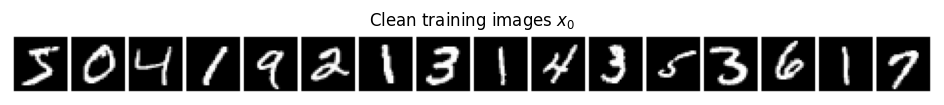

In [2]:
mnist_train = torchvision.datasets.MNIST(DATA_DIR, train=True, download=True)
mnist_test = torchvision.datasets.MNIST(DATA_DIR, train=False, download=True)
X_train = (mnist_train.data.float() / 255 * 2 - 1).unsqueeze(1).to(DEVICE)    # (60000, 1, 28, 28), values in [-1, 1]
X_test = (mnist_test.data.float() / 255 * 2 - 1).unsqueeze(1).to(DEVICE)      # (10000, 1, 28, 28)
print("training images:", tuple(X_train.shape), "| value range:", X_train.min().item(), "to", X_train.max().item())
show_grid(X_train[:16], nrow=16, title="Clean training images $x_0$", size=12)

## 3. Gaussian noise, and why it is not blur

Diffusion models corrupt images by **adding Gaussian noise**. This section defines it, shows what it looks like, and contrasts it with blur, a different corruption that is easy to confuse with it.

### 3.1 What Gaussian noise is

**Gaussian noise is a tensor of random numbers, one per pixel, each drawn independently from a normal distribution with mean 0 and standard deviation 1.** In PyTorch it is one call: `torch.randn_like(x)`.

- **One number per pixel.** `torch.randn_like(x)` returns a tensor with the same shape as `x`. For an MNIST image, `(1, 28, 28)`, that is 784 numbers.
- **Normal distribution (the bell curve).** Values near 0 are the most likely and large values are rare: about 68% lie within ±1, about 95% within ±2, and almost none beyond ±3.
- **Mean 0.** Positive and negative values balance, so adding noise does not make the image brighter or darker on average.
- **Standard deviation 1.** This sets the typical size of a value. Our pixels lie in $[-1, 1]$, so unscaled noise is as large as the image itself; Section 4 scales it down at small timesteps.
- **Independent.** Each pixel's number is drawn separately, so knowing one pixel's noise tells you nothing about its neighbours'.
- **Adding noise is pixel by pixel.** $x + \epsilon$ adds each pixel's own random number to that pixel's value.

### 3.2 The notation $\epsilon \sim \mathcal{N}(0, I)$

We write the noise as $\epsilon \sim \mathcal{N}(0, I)$, read "epsilon is drawn from a normal distribution with mean $0$ and covariance matrix $I$". You may know the normal distribution as $\mathcal{N}(\mu, \sigma^2)$, with a mean and a **variance**. Here the second argument is a **covariance matrix** instead, because $\epsilon$ is not one number but 784 of them. Three steps get us there.

**Step 1: one pixel needs a mean and a variance.** A single random number $z \sim \mathcal{N}(\mu, \sigma^2)$ has:

- a **mean** $\mu = \mathbb{E}[z]$, its average value;
- a **variance** $\sigma^2 = \operatorname{Var}(z) = \mathbb{E}\big[(z - \mu)^2\big]$, the average squared distance from the mean. Its square root $\sigma$ is the standard deviation.

Each pixel of our noise, on its own, is $\mathcal{N}(0, 1)$: mean 0, variance 1.

**Step 2: two pixels also need a covariance.** Variances describe each pixel separately, but not whether two pixels move together. The **covariance** measures that:

$$\operatorname{Cov}(\epsilon_i, \epsilon_j) = \mathbb{E}\big[(\epsilon_i - \mu_i)(\epsilon_j - \mu_j)\big]$$

- **Positive:** when one pixel is above its mean, the other tends to be above its mean too, as neighbouring pixels in a blurred image are.
- **Zero:** the two pixels have no linear relationship.
- **Negative:** when one is above its mean, the other tends to be below.
- **A pixel with itself:** $\operatorname{Cov}(\epsilon_i, \epsilon_i) = \operatorname{Var}(\epsilon_i)$. Variance is the special case of covariance with $i = j$.

The **correlation** printed by the next cell is the covariance rescaled to lie between −1 and 1: $\operatorname{Cov}(\epsilon_i, \epsilon_j) / (\sigma_i \sigma_j)$.

**Step 3: a whole image needs a covariance matrix.** For a vector of $d$ pixels, collect every covariance in a $d \times d$ matrix $\Sigma$ with entries $\Sigma_{ij} = \operatorname{Cov}(\epsilon_i, \epsilon_j)$:

- the **diagonal** entries ($i = j$) are the $d$ variances;
- the **off-diagonal** entries ($i \ne j$) are the covariances of every pair of pixels.

A normal distribution over vectors, a **multivariate normal**, is written $\mathcal{N}(\boldsymbol{\mu}, \Sigma)$: a mean vector and a covariance matrix. This is why covariance replaces variance. One variance describes one number; 784 numbers need 784 variances **and** a covariance for every pair. For MNIST, $\Sigma$ is a 784 × 784 matrix.

**Why the covariance matrix is $I$.** Two properties of our noise each fill one part of $\Sigma$:

| Property of the noise (3.1) | Part of $\Sigma$ it sets | Value |
| --- | --- | --- |
| Every pixel has variance 1 | Diagonal | All 1 |
| Pixels are drawn independently, so different pixels have covariance 0 | Off-diagonal | All 0 |

A matrix with 1s on the diagonal and 0s everywhere else is the **identity matrix** $I$. The mean $0$ is the mean vector, 784 zeros. For an image of just two pixels:

$$\begin{pmatrix}\epsilon_1 \\ \epsilon_2\end{pmatrix} \sim \mathcal{N}\!\left(\begin{pmatrix}0 \\ 0\end{pmatrix},\ \begin{pmatrix}1 & 0 \\ 0 & 1\end{pmatrix}\right)$$

So $\epsilon \sim \mathcal{N}(0, I)$ packs the whole definition in 3.1 into one expression: 784 independent $\mathcal{N}(0, 1)$ numbers. (For a normal distribution, zero covariance means independence. For other distributions it need not.)

**Two points to watch.**

- **Variance, not standard deviation.** In this notation the second argument is a variance (or covariance matrix). PyTorch's `torch.normal(mean, std)` takes a standard deviation instead. With variance 1 the two agree, because $\sqrt{1} = 1$, but in Section 4 they do not: noise scaled by $\sqrt{1 - \bar\alpha_t}$ has standard deviation $\sqrt{1 - \bar\alpha_t}$ and variance $1 - \bar\alpha_t$.
- **Where it appears next.** $\mathcal{N}(0, I)$ is part of Section 4's main equation.

### 3.3 What "static" means

**Static** is the usual name for an image of pure noise: random speckle with no pattern, like the "snow" on an old analogue TV tuned to no channel. It has no pattern **because** the pixels are independent: no pixel is related to its neighbours, so no edges, strokes or blobs can form.

The cell below shows one digit four ways (clean, the noise $\epsilon$ alone, image plus noise, blurred), prints a few noise values, and checks the bell curve and the independence of neighbouring pixels.

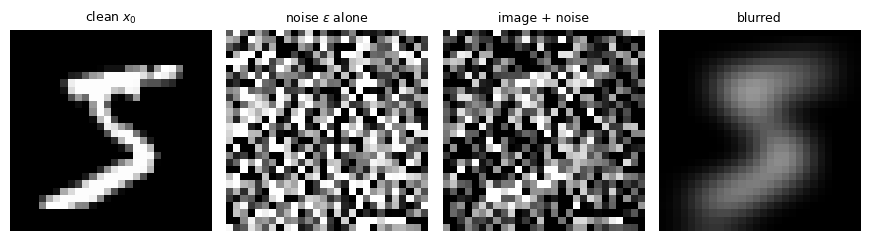

Top-left 3 x 3 corner of the noise (one random number per pixel):
[[-0.3   2.68 -0.14]
 [ 0.41  0.19 -1.54]
 [-0.29 -0.69 -0.94]]

All 784 values: mean -0.032, standard deviation 1.021
share within ±1: 66%   share within ±2: 96%

Correlation between horizontally neighbouring pixels:
  noise:         -0.00
  blurred noise: 0.94


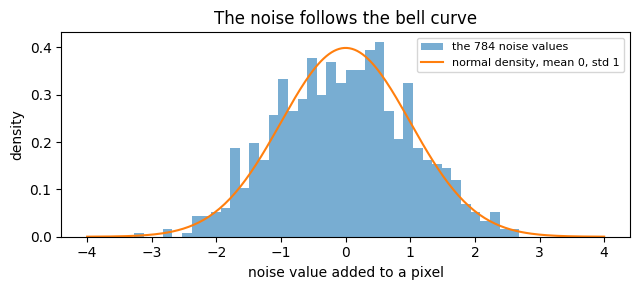

In [3]:
digit = X_train[0]                                            # one image, (1, 28, 28), values in [-1, 1]
torch.manual_seed(1)
eps = torch.randn_like(digit)                                 # Gaussian noise: one N(0, 1) number per pixel, same shape as the image
noisy = 0.6 * digit + 0.8 * eps                               # image + noise; 0.6² + 0.8² = 1, the form of x_t in Section 4
blurred = TF.gaussian_blur(digit, kernel_size=9, sigma=2.5)   # each pixel -> weighted average of its 9 × 9 neighbourhood
show_row([digit, eps, noisy, blurred], ["clean $x_0$", "noise $\\epsilon$ alone", "image + noise", "blurred"], size=2.2)

# A small numerical view of the noise.
print("Top-left 3 x 3 corner of the noise (one random number per pixel):")
print(eps[0, :3, :3].cpu().numpy().round(2))
vals = eps.flatten().cpu()
print(f"\nAll {vals.numel()} values: mean {vals.mean():.3f}, standard deviation {vals.std():.3f}")
print(f"share within ±1: {(vals.abs() <= 1).float().mean():.0%}   share within ±2: {(vals.abs() <= 2).float().mean():.0%}")


def neighbour_corr(img):
    """Correlation between each pixel and its right-hand neighbour, over the whole image."""
    left, right = img[..., :, :-1].flatten(), img[..., :, 1:].flatten()
    return torch.corrcoef(torch.stack([left, right]))[0, 1].item()


print("\nCorrelation between horizontally neighbouring pixels:")
print(f"  noise:         {neighbour_corr(eps):.2f}")
print(f"  blurred noise: {neighbour_corr(TF.gaussian_blur(eps, kernel_size=9, sigma=2.5)):.2f}")

grid = torch.linspace(-4, 4, 200)
plt.figure(figsize=(6.5, 3))
plt.hist(vals, bins=40, density=True, alpha=0.6, label=f"the {vals.numel()} noise values")
plt.plot(grid, torch.exp(-grid ** 2 / 2) / math.sqrt(2 * math.pi), label="normal density, mean 0, std 1")
plt.xlabel("noise value added to a pixel"); plt.ylabel("density")
plt.title("The noise follows the bell curve"); plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Reading the output.**

- **The four panels.**
  - *Noise alone* is static: speckle with no structure. Values beyond ±1, about a third of them, are clipped to black or white for display only.
  - *Image + noise*: speckle covers the background as well as the stroke, yet the 5 is still visible as a brighter region. Because $0.6^2 + 0.8^2 = 1$, this is exactly the kind of image Section 4 calls $x_t$; in our schedule it corresponds to about $t = 314$.
  - *Blurred*: still readable as a 5, with soft edges and no speckle.
- **The histogram.** The bars follow the bell curve: many small values, few large ones.
- **The neighbour correlation.** Near 0 for noise, because its pixels are independent: this is the off-diagonal 0 of $I$ (3.2), measured on one image. Close to 1 for blurred noise, because blur makes neighbours alike; its covariance matrix is far from $I$. That is the defining difference between the two corruptions.

### 3.4 Noise vs. blur

| | Gaussian noise | Blur |
| --- | --- | --- |
| Operation | Adds an independent random number to each pixel | Replaces each pixel by a weighted average of its neighbours |
| Random? | Yes: different every time | No: the same input always gives the same output |
| Neighbouring pixels | Stay unrelated (correlation near 0) | Become more alike (correlation near 1) |
| What happens to the image | Fine detail is drowned out; heavy noise buries the digit | Edges soften; the overall shape survives |
| End point of heavy corruption | Pure noise $\mathcal{N}(0, I)$, the same whatever image we started from | A smooth, featureless blob whose brightness still depends on the image |

### 3.5 Why diffusion uses noise

1. Adding Gaussian noise many times still gives Gaussian noise. That is what makes Section 4's one-step equation possible.
2. Heavy noise ends at the same simple distribution, $\mathcal{N}(0, I)$, whatever image we started from.
3. We can draw fresh samples from that distribution with one line, `torch.randn`. That gives generation its starting point.
4. Blur has neither property. Heavy blur ends at a blob that depends on the image, and it is deterministic, so it offers no random starting point and no source of variety.

Diffusion models in this course therefore add noise, never blur.

## 4. The forward process: adding noise gradually—and jumping to any noise level

The **forward diffusion process** is a fixed mathematical recipe that gradually turns a clean image into noise. It does this over a sequence of small steps. In this section, we use $T=1000$ steps.

Although the process is written as 1000 successive steps, a useful formula lets us generate a noisy version of a clean image at **any chosen timestep directly**. We do not have to simulate all the earlier steps.

The forward process gives the model training examples to learn from. The reverse process, introduced later, learns how to remove the noise and generate images.

| | Forward process | Reverse process |
|---|---|---|
| Direction | Clean image $x_0$ $\rightarrow$ noise $x_T$ | Noise $x_T$ $\rightarrow$ generated image |
| Learned? | **No.** It is a fixed recipe chosen by the designer. | **Yes.** A neural network learns to reverse the corruption. |
| Purpose | Create noisy training examples. | Generate images by progressively removing noise. |
| Computation | Simple arithmetic and Gaussian noise sampling. | A neural-network evaluation at each reverse step. |

The section builds up in this order: one noising step (4.1), the variance rules needed to analyse it (4.2), why the image is shrunk as noise is added (4.3), the meaning of $\alpha_t$ and $\beta_t$ (4.4), the one-jump formula (4.5), and how to interpret that formula (4.6). The code and its outputs follow in Sections 4.7–4.10.

### Notation

| Symbol | Meaning | Shape for one MNIST image |
|---|---|---|
| $x_0$ | Clean image, with pixel values scaled to $[-1,1]$ | $1\times28\times28$ |
| $x_t$ | Image after $t$ forward-noising steps | $1\times28\times28$ |
| $T$ | Total number of noising steps; here, $1000$ | Scalar |
| $\beta_t$ | Variance of the fresh Gaussian noise added at step $t$ | Scalar |
| $\alpha_t=1-\beta_t$ | Coefficient controlling how much of the previous image is retained in the variance calculation | Scalar |
| $\bar\alpha_t=\prod_{s=1}^{t}\alpha_s$ | Cumulative product of the $\alpha$ values up to step $t$ | Scalar |
| $\epsilon_t$ | Fresh standard Gaussian noise, $\epsilon_t\sim\mathcal N(0,I)$ | $1\times28\times28$ |

Here, $I$ is the identity covariance matrix. In practical terms, each pixel receives independent standard Gaussian noise with mean 0 and variance 1.

### 4.1 One step of noising

Each forward step does two things: it **slightly shrinks the current image** and then **adds a small amount of fresh Gaussian noise**.

$$
\boxed{
 x_t=\underbrace{\sqrt{1-\beta_t}\,x_{t-1}}_{\text{1. shrink the previous image}}
 +\underbrace{\sqrt{\beta_t}\,\epsilon_t}_{\text{2. add fresh noise}},
 \qquad \epsilon_t\sim\mathcal N(0,I)
}
$$

The two operations are:

1. **Shrink:** multiply the previous image by $\sqrt{1-\beta_t}$, a number slightly smaller than 1. This reduces the contribution of the previous image.
2. **Add noise:** add fresh Gaussian noise multiplied by $\sqrt{\beta_t}$. Since multiplying a random variable by a constant multiplies its variance by the square of that constant, the added noise has variance $\beta_t$.

The sequence $\beta_1,\ldots,\beta_T$ is called the **noise schedule**. It determines how much noise is added at each step. We use the linear schedule from Ho et al. (2020), in which $\beta_t$ increases linearly from $0.0001$ at the first step to $0.02$ at the final step.

| Step | $\beta_t$ | Shrink factor $\sqrt{1-\beta_t}$ | Noise scale $\sqrt{\beta_t}$ |
|---|---:|---:|---:|
| First | 0.0001 | 0.99995 | 0.010 |
| Last | 0.02 | 0.990 | 0.141 |

Early steps make very small changes, so the image is not destroyed immediately. Later steps add somewhat more noise. (Lecture 2 compares this linear schedule with a cosine schedule.)

The next sections answer three questions: why shrink the image at all, why use square roots in the equation, and how can we skip the intermediate steps?

### 4.2 Two rules about variance

To analyse a noising step, we use two familiar rules about variance. For a random variable $Z$,

$$
\operatorname{Var}(Z)=\mathbb E\left[(Z-\mu_Z)^2\right],
\qquad \mu_Z=\mathbb E[Z].
$$

Variance measures the average squared deviation from the mean.

#### Rule 1: A constant multiplier is squared

$$
\boxed{\operatorname{Var}(cZ)=c^2\operatorname{Var}(Z)}
$$

**Why?** The mean of $cZ$ is $c\mu_Z$. Therefore,

$$
\begin{aligned}
\operatorname{Var}(cZ)
&=\mathbb E\left[(cZ-c\mu_Z)^2\right]\\
&=\mathbb E\left[c^2(Z-\mu_Z)^2\right]\\
&=c^2\mathbb E\left[(Z-\mu_Z)^2\right]\\
&=c^2\operatorname{Var}(Z).
\end{aligned}
$$

The multiplier is squared because variance is based on **squared deviations**. For example, doubling every value doubles every deviation, so the squared deviations—and therefore the variance—become four times as large.

#### Rule 2: Variances add when the variables are independent

If $X$ and $Y$ are independent, then

$$
\boxed{\operatorname{Var}(X+Y)=\operatorname{Var}(X)+\operatorname{Var}(Y)}
$$

To see why, define each variable's deviation from its mean:

$$
a=X-\mu_X,\qquad b=Y-\mu_Y.
$$

The deviation of $X+Y$ from its mean is $a+b$. Expanding the square gives

$$
\begin{aligned}
\operatorname{Var}(X+Y)
&=\mathbb E[(a+b)^2]\\
&=\mathbb E[a^2]+2\mathbb E[ab]+\mathbb E[b^2]\\
&=\operatorname{Var}(X)+2\operatorname{Cov}(X,Y)+\operatorname{Var}(Y).
\end{aligned}
$$

This is the **general formula**:

$$
\boxed{\operatorname{Var}(X+Y)=\operatorname{Var}(X)+\operatorname{Var}(Y)+2\operatorname{Cov}(X,Y)}
$$

Independence implies zero covariance. In that case, the middle term disappears and the variances add.

Independence matters. For example, if $Y=X$, then

$$
\operatorname{Var}(X+X)=\operatorname{Var}(2X)=4\operatorname{Var}(X),
$$

not $2\operatorname{Var}(X)$.

#### Apply the two rules to one diffusion step

In the forward process, the previous noisy image $x_{t-1}$ and the newly sampled noise $\epsilon_t$ are independent:

- $x_{t-1}$ depends on the clean image and the earlier noise samples $\epsilon_1,\ldots,\epsilon_{t-1}$.
- $\epsilon_t$ is a fresh sample, generated independently at the current step.
- Therefore, knowing $x_{t-1}$ gives no information about $\epsilon_t$.

For a single pixel (or, equivalently, for the covariance matrix of the whole image), the two variance rules give

$$
\begin{aligned}
\operatorname{Var}(x_t)
&=\operatorname{Var}\left(\sqrt{1-\beta_t}\,x_{t-1}
 +\sqrt{\beta_t}\,\epsilon_t\right)\\
&=\operatorname{Var}\left(\sqrt{1-\beta_t}\,x_{t-1}\right)
 +\operatorname{Var}\left(\sqrt{\beta_t}\,\epsilon_t\right)\\
&=(1-\beta_t)\operatorname{Var}(x_{t-1})
 +\beta_t\operatorname{Var}(\epsilon_t)\\
&=(1-\beta_t)\operatorname{Var}(x_{t-1})+\beta_t,
\end{aligned}
$$

because each component of standard Gaussian noise has variance 1.

Thus,

$$
\boxed{
\operatorname{Var}(x_t)
=\underbrace{(1-\beta_t)\operatorname{Var}(x_{t-1})}_{\text{contribution from the previous image}}
+\underbrace{\beta_t}_{\text{contribution from fresh noise}}
}
$$

For the whole image, the corresponding covariance-matrix equation is

$$
\boxed{\operatorname{Cov}(x_t)
=(1-\beta_t)\operatorname{Cov}(x_{t-1})+\beta_t I.}
$$


### 4.3 Why each step shrinks the image

Why not simply keep the image unchanged and add noise? Why multiply it by a number slightly smaller than 1 at every step?

The shrinkage serves two related purposes:

1. **Make the final distribution independent of the starting image.** Generation will start from a fresh sample of $\mathcal N(0,I)$. We therefore want the forward process to turn every training image into something very close to that same standard Gaussian distribution, with almost no information about which image we started from.
2. **Keep the scale of the noisy data controlled.** We do not want the magnitude of the noise to grow without bound as the steps accumulate.

#### What goes wrong without shrinkage?

Suppose we used

$$
x_t=x_{t-1}+\sqrt{\beta_t}\,\epsilon_t.
$$

The original image is never reduced. The added noise accumulates from step to step. Since the noise samples are independent, their variances add:

$$
\operatorname{Var}(\text{accumulated noise})
=\beta_1+\cdots+\beta_{1000}.
$$

For the linear schedule from 0.0001 to 0.02, this sum is 10.05. The accumulated noise therefore has standard deviation

$$
\sqrt{10.05}\approx3.17.
$$

But the original image remains fully present. For example, if a particular pixel starts at $x_0=+1$, its value after all steps has mean $+1$, not 0. A pixel that starts at $-1$ still has mean $-1$. The final result therefore retains information about the original image; it is not approximately the same standard Gaussian distribution for every starting image.

#### What changes when we include shrinkage?

With shrinkage, the multiplier on the original image is applied repeatedly. The cumulative multiplier on $x_0$ is

$$
\sqrt{\alpha_1}\sqrt{\alpha_2}\cdots\sqrt{\alpha_T}
=\sqrt{\bar\alpha_T},
$$

where

$$
\bar\alpha_t=\alpha_1\alpha_2\cdots\alpha_t.
$$

For the 1000-step linear schedule, $\bar\alpha_T$ is about $4.0\times10^{-5}$, so the multiplier on the original image is only

$$
\sqrt{\bar\alpha_T}\approx0.006.
$$

A starting pixel value of $+1$ therefore contributes only about $+0.006$ to the final pixel's mean; a starting value of $-1$ contributes about $-0.006$. The original image's influence has become negligible.

At the same time, the accumulated noise variance approaches 1. The final pixel is therefore approximately distributed as $\mathcal N(0,1)$, regardless of its original value. For the whole image, the endpoint is approximately $\mathcal N(0,I)$.

| One pixel after all 1000 steps | Mean | Standard deviation | Does it forget the starting pixel? |
|---|---:|---:|---|
| No shrinkage, starting at $+1$ | $+1$ | $\approx3.17$ | No; the mean still depends on the image. |
| No shrinkage, starting at $-1$ | $-1$ | $\approx3.17$ | No; the mean still depends on the image. |
| With shrinkage, starting at $+1$ | $\approx+0.006$ | $\approx1$ | Almost; the starting value has negligible influence. |
| With shrinkage, starting at $-1$ | $\approx-0.006$ | $\approx1$ | Almost; the starting value has negligible influence. |

The purpose of shrinkage is therefore not merely to make the image look dimmer. It gradually removes the starting image's contribution while the injected noise builds up to a controlled, unit-variance Gaussian distribution.

### 4.4 What $\alpha_t$ and $\beta_t$ mean—and why they add to 1

For convenience, define

$$
\boxed{\alpha_t=1-\beta_t.}
$$

The one-step equation and its variance recurrence become

$$
\boxed{x_t=\sqrt{\alpha_t}\,x_{t-1}+\sqrt{\beta_t}\,\epsilon_t}
$$

and

$$
\boxed{\operatorname{Var}(x_t)
=\alpha_t\operatorname{Var}(x_{t-1})+\beta_t.}
$$

So what do the two coefficients do?

- $\alpha_t$ controls how much of the previous image's variance is carried into the next step.
- $\beta_t$ is the variance contributed by the new standard Gaussian noise.

They add to 1 **because the DDPM schedule defines** $\alpha_t=1-\beta_t$. This is a design choice called a **variance-preserving** parameterization.

To see the reason for the choice, suppose the previous image has variance 1. Then

$$
\begin{aligned}
\operatorname{Var}(x_t)
&=\alpha_t\cdot1+\beta_t\\
&=\alpha_t+\beta_t\\
&=1.
\end{aligned}
$$

The variance removed by shrinking the previous signal is balanced by the variance introduced by the new noise. The total stays at 1.

For example, if $\beta_t=0.02$, then $\alpha_t=0.98$:

| Contribution to the next-step variance, assuming previous variance is 1 | Value |
|---|---:|
| Carried over from the previous image: $\alpha_t$ | 0.98 (98%) |
| Added by the new noise: $\beta_t$ | 0.02 (2%) |
| **Total** | **1.00 (100%)** |

At the first step, where $\beta_t=0.0001$, the corresponding values are 0.9999 and 0.0001. At the last step, where $\beta_t=0.02$, they are 0.98 and 0.02.

**Important qualification:** $\alpha_t$ and $\beta_t$ are exactly complementary coefficients. They can be interpreted as two shares of a unit variance when the previous variance is 1. Real MNIST pixels do not have exactly unit variance, so the total data variance need not be exactly 1 at every finite timestep. The recurrence

$$
v_t=\alpha_t v_{t-1}+\beta_t
$$

moves the variance toward 1: subtracting 1 from both sides gives

$$
v_t-1=\alpha_t(v_{t-1}-1).
$$

Because $0<\alpha_t<1$, any difference from unit variance is progressively reduced. By the final steps, the contribution of the original data distribution is tiny and the noise scale is close to unit variance.

This also explains why the square roots appear in the image equation. Variance squares a multiplier, so using $\sqrt{\alpha_t}$ and $\sqrt{\beta_t}$ produces variance coefficients $\alpha_t$ and $\beta_t$.

### 4.5 From many steps to one jump

We do not need to execute all the forward steps to obtain $x_t$. We can derive a direct formula that samples the same distribution in one jump from $x_0$.

#### Work through two steps

The first two forward steps are

$$
\begin{aligned}
x_1&=\sqrt{\alpha_1}\,x_0+\sqrt{\beta_1}\,\epsilon_1,\\
x_2&=\sqrt{\alpha_2}\,x_1+\sqrt{\beta_2}\,\epsilon_2.
\end{aligned}
$$

Substitute the expression for $x_1$ into the second equation:

$$
x_2
=\sqrt{\alpha_2}\left(\sqrt{\alpha_1}\,x_0+\sqrt{\beta_1}\,\epsilon_1\right)+\sqrt{\beta_2}\,\epsilon_2
=\sqrt{\alpha_1\alpha_2}\,x_0+n,
\qquad
n=\sqrt{\alpha_2\beta_1}\,\epsilon_1+\sqrt{\beta_2}\,\epsilon_2.
$$

The first term is what remains of the clean image; $n$ is the **accumulated noise**.

**Its variance.** $\epsilon_1$ and $\epsilon_2$ are independent, each with variance 1. By Rule 2 (independent variances add) and Rule 1 (constants come out squared) of Section 4.2:

$$
\operatorname{Var}(n)=\alpha_2\beta_1+\beta_2=\alpha_2(1-\alpha_1)+(1-\alpha_2)=1-\alpha_1\alpha_2.
$$

**Two noise samples become one.** Define $\epsilon=n/\sqrt{1-\alpha_1\alpha_2}$, the accumulated noise rescaled to unit variance. Then $n=\sqrt{1-\alpha_1\alpha_2}\,\epsilon$ exactly, and $\epsilon$ is a standard Gaussian:

- **Gaussian**, because a weighted sum of independent Gaussians is Gaussian;
- **mean 0**, because $\epsilon_1$ and $\epsilon_2$ have mean 0;
- **variance 1**, by Rule 1: $\operatorname{Var}(\epsilon)=(1-\alpha_1\alpha_2)/(1-\alpha_1\alpha_2)=1$.

So

$$
\boxed{x_2=\sqrt{\alpha_1\alpha_2}\,x_0
 +\sqrt{1-\alpha_1\alpha_2}\,\epsilon,\qquad
 \epsilon\sim\mathcal N(0,I).}
$$

$\epsilon$ keeps the total noise but not how it was split between the two steps. That split is never needed: drawing one $\epsilon$ gives $x_2$ exactly the same distribution as drawing $\epsilon_1$ and $\epsilon_2$. This step works only because the noise is Gaussian; the sum of two uniform samples, for example, is not uniform.

#### Generalise to any timestep

Define the cumulative product

$$
\boxed{\bar\alpha_t=\prod_{s=1}^{t}\alpha_s
=\alpha_1\alpha_2\cdots\alpha_t.}
$$

The same argument extends one step at a time. If $x_{t-1}=\sqrt{\bar\alpha_{t-1}}\,x_0+\sqrt{1-\bar\alpha_{t-1}}\,\epsilon'$, one more step gives

$$
x_t=\sqrt{\alpha_t\bar\alpha_{t-1}}\,x_0+\sqrt{\alpha_t(1-\bar\alpha_{t-1})}\,\epsilon'+\sqrt{\beta_t}\,\epsilon_t.
$$

The signal coefficient is $\sqrt{\bar\alpha_t}$. The noise variance is $\alpha_t(1-\bar\alpha_{t-1})+(1-\alpha_t)=1-\bar\alpha_t$, and the two noise terms again combine into one. Starting from step 1, where $\bar\alpha_1=\alpha_1$, this gives for every $t$:

$$
\boxed{
 x_t=\sqrt{\bar\alpha_t}\,x_0
 +\sqrt{1-\bar\alpha_t}\,\epsilon,
 \qquad \epsilon\sim\mathcal N(0,I).
}
$$

This is the **one-jump formula** and is one of the most important equations in DDPM.

Equivalently, the distribution of a noisy image at timestep $t$, given the clean image, is

$$
\boxed{q(x_t\mid x_0)
=\mathcal N\left(\sqrt{\bar\alpha_t}\,x_0,
 (1-\bar\alpha_t)I\right).}
$$

The formula gives the same **distribution** as applying the steps one by one. It does not reproduce the exact same random sample that a particular sequence of noise draws would have produced. For training, matching the distribution is what matters.

| | Step-by-step | One-jump formula |
|---|---|---|
| To obtain $x_{500}$ | 500 updates and 500 noise draws | One multiplication and one noise draw |
| Distribution of the result | $q(x_{500}\mid x_0)$ | The same $q(x_{500}\mid x_0)$ |

This makes training efficient. We can choose a random timestep for each training example and construct the corresponding noisy image directly. Producing $x_3$ or $x_{870}$ takes essentially the same amount of forward-noising work.

### 4.6 How to read the one-jump formula

Return to

$$
x_t=\sqrt{\bar\alpha_t}\,x_0
 +\sqrt{1-\bar\alpha_t}\,\epsilon.
$$

It combines the clean image with fresh Gaussian noise. As $t$ increases, the contribution from the clean image decreases and the contribution from noise increases.

| Quantity | Meaning | Small $t$ | Large $t$ |
|---|---|---|---|
| $\bar\alpha_t$ | Cumulative signal-variance coefficient | Close to 1 | Close to 0 |
| $\sqrt{\bar\alpha_t}$ | Multiplier on the clean image | Close to 1 | Close to 0 |
| $\sqrt{1-\bar\alpha_t}$ | Multiplier on fresh noise | Close to 0 | Close to 1 |

Three details are worth remembering:

1. **The squared coefficients add to 1—not the coefficients themselves.** The image and noise multipliers are square roots. Their squares are $\bar\alpha_t$ and $1-\bar\alpha_t$, which add to 1. For example, the combination $0.6x_0+0.8\epsilon$ has this form because $0.6^2+0.8^2=1$.
2. **$\bar\alpha_t$ is a variance coefficient, not the pixel multiplier.** The actual multiplier on the clean image is $\sqrt{\bar\alpha_t}$. For example, if $\bar\alpha_t=0.52$, the image multiplier is $\sqrt{0.52}\approx0.72$.
3. **The formula is exact even when the clean data do not have unit variance.** Conditioned on a particular clean image, the injected-noise covariance is exactly $(1-\bar\alpha_t)I$. Across the dataset, the covariance is

   $$
   \operatorname{Cov}(x_t)
   =\bar\alpha_t\operatorname{Cov}(x_0)
   +(1-\bar\alpha_t)I,
   $$

   because the sampled noise is independent of the clean image. Thus, if the clean data do not have unit covariance, the overall covariance is not exactly $I$ at every timestep. It approaches $I$ as $\bar\alpha_t$ approaches zero.

At the final timestep, $\bar\alpha_T$ is very close to zero. The clean-image multiplier is therefore almost zero, while the noise multiplier is almost one:

$$
x_T\approx\epsilon,\qquad \epsilon\sim\mathcal N(0,I).
$$

In other words, the final noisy image is approximately standard Gaussian noise, regardless of which training image we started with. This is what allows the reverse generative process to begin with a fresh sample from $\mathcal N(0,I)$.

---

**The central idea to remember:** the forward process gradually reduces the clean image's contribution and replaces it with Gaussian noise. The coefficients are chosen so that the noise scale remains controlled, and the cumulative-product formula lets us create a noisy image at any timestep in one step.

    t  alpha_bar  image weight  noise weight
    0     0.9999         1.000         0.010
   50     0.9700         0.985         0.173
  100     0.8951         0.946         0.324
  250     0.5214         0.722         0.692
  500     0.0778         0.279         0.960
  750     0.0033         0.057         0.998
  999     0.0000         0.006         1.000


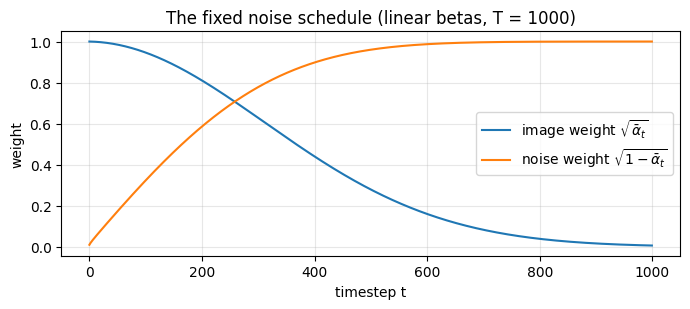

In [4]:
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=DEVICE)          # linear schedule of Ho et al. (2020)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)                     # alpha_bar[t] = product of alphas[0..t]

print(f"{'t':>5}{'alpha_bar':>11}{'image weight':>14}{'noise weight':>14}")
for t in (0, 50, 100, 250, 500, 750, 999):
    ab = alpha_bars[t].item()
    print(f"{t:>5}{ab:>11.4f}{math.sqrt(ab):>14.3f}{math.sqrt(1 - ab):>14.3f}")

plt.figure(figsize=(7, 3.2))
plt.plot(alpha_bars.sqrt().cpu(), label=r"image weight $\sqrt{\bar\alpha_t}$")
plt.plot((1 - alpha_bars).sqrt().cpu(), label=r"noise weight $\sqrt{1-\bar\alpha_t}$")
plt.xlabel("timestep t"); plt.ylabel("weight"); plt.title("The fixed noise schedule (linear betas, T = 1000)")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### 4.7 Reading the schedule

`betas`, `alphas` and `alpha_bars` are $\beta_t$, $\alpha_t = 1 - \beta_t$ and $\bar\alpha_t$; `torch.cumprod` computes the running product. Code indexes the steps from 0, so `alpha_bars[t]` is $\bar\alpha_{t+1}$ in the 1-based maths above. With 1000 steps the difference is invisible, and the rest of the notebook labels timesteps by code index.

| $t$ | $\bar\alpha_t$ (variance from $x_0$) | Image weight | Noise weight | Digit in the strip below |
| ---: | ---: | ---: | ---: | --- |
| 0 | 0.9999 | 1.000 | 0.010 | clean |
| 50 | 0.9700 | 0.985 | 0.173 | light grain |
| 100 | 0.8951 | 0.946 | 0.324 | clear |
| 250 | 0.5214 | 0.722 | 0.692 | barely visible |
| 500 | 0.0778 | 0.279 | 0.960 | gone |
| 750 | 0.0033 | 0.057 | 0.998 | noise |
| 999 | 0.0000 | 0.006 | 1.000 | noise |

1. **Slow, then fast.** $\bar\alpha_t$ falls slowly at first, because the early $\beta_t$ are tiny, and then quickly, because the later $\beta_t$ are larger.
2. **The crossing.** The two curves cross where $\bar\alpha_t = 0.5$, just after $t = 250$; from there on the noise outweighs the image.
3. **Per step vs. cumulative.** Every single step keeps $\alpha_t \ge 0.98$ of the previous variance, yet the product $\bar\alpha_t$ falls to 0: the image is replaced gradually, not by any one big step.
4. **The tail.** The last few hundred steps change almost nothing visible: they push the image weight from $0.057$ to $0.006$.

### 4.8 The forward process in code

The one-jump formula is two lines of code. The only subtlety is **shape**: each image in a batch may have its own timestep.

| Expression | Shape | What it is |
| --- | --- | --- |
| `x0`, `noise` | `(B, 1, 28, 28)` | clean images and their noise, one $\epsilon$ per image |
| `t` | `(B,)` | one integer timestep **per image**; they can differ |
| `alpha_bars[t]` | `(B,)` | $\bar\alpha_t$ looked up for each image |
| `.view(-1, 1, 1, 1)` | `(B, 1, 1, 1)` | three size-1 axes added |
| `ab.sqrt() * x0` | `(B, 1, 28, 28)` | broadcasting applies each image's weight to all 784 of its pixels |
| returned $x_t$ | `(B, 1, 28, 28)` | same shape as `x0` |

- **Why the reshape.** Without it, PyTorch would line up the `(B,)` axis with the **last** axis of `x0` (width 28): an error for most batch sizes, and silently wrong weights across columns when $B = 28$.
- **Mixed timesteps.** `t = tensor([0, 500])` weights image 0 by $\sqrt{0.9999}$ (almost unchanged) and image 1 by $\sqrt{0.0778}$ (mostly noise), in the same call.

The cell below uses `add_noise` twice:

1. **The strip.** One digit, copied 7 times with `expand`, is noised at 7 timesteps with 7 independent noises. Every panel is made **directly from $x_0$** in one jump, not from the panel before it.
2. **The endpoint check.** 512 training images are noised to $t = 999$, and their mean and standard deviation are compared with pure $\mathcal{N}(0, 1)$ noise.

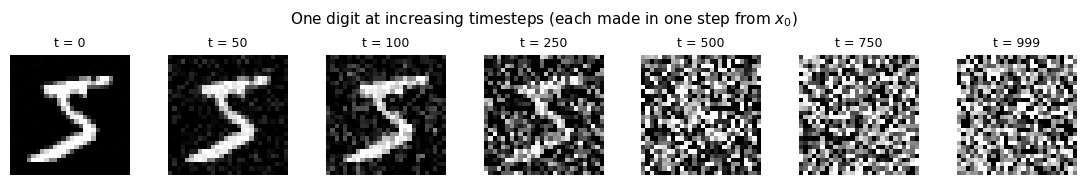

clean images: mean -0.748, std 0.605
x_T:          mean -0.003, std 0.999   (pure Gaussian noise would give 0 and 1)


In [5]:
def add_noise(x0, t, noise):
    """The forward process in one step: x_t = sqrt(alpha_bar_t) * x0 + sqrt(1 - alpha_bar_t) * noise.
    x0, noise: (B, C, H, W); t: (B,) integer timesteps. Returns x_t with the same shape as x0."""
    ab = alpha_bars[t].view(-1, 1, 1, 1)                      # (B,) -> (B, 1, 1, 1) for broadcasting
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise


steps = torch.tensor([0, 50, 100, 250, 500, 750, 999], device=DEVICE)
torch.manual_seed(2)
views = add_noise(digit.expand(len(steps), -1, -1, -1), steps, torch.randn(len(steps), 1, 28, 28, device=DEVICE))
show_row(views, [f"t = {t}" for t in steps.tolist()], suptitle="One digit at increasing timesteps (each made in one step from $x_0$)")

batch = X_train[:512]
x_T = add_noise(batch, torch.full((512,), T - 1, device=DEVICE), torch.randn_like(batch))
print(f"clean images: mean {batch.mean():.3f}, std {batch.std():.3f}")
print(f"x_T:          mean {x_T.mean():.3f}, std {x_T.std():.3f}   (pure Gaussian noise would give 0 and 1)")

### 4.9 Reading the output

**The strip.** The digit is clear at $t = 100$, barely visible at $t = 250$, and gone from $t = 500$ on.

**The endpoint check.**

| | Mean | Standard deviation |
| --- | ---: | ---: |
| clean digits (512 images) | $-0.748$ | $0.605$ |
| $x_T$ from those digits | $-0.003$ | $0.999$ |
| pure $\mathcal{N}(0, 1)$ noise | $0$ | $1$ |

The clean digits have a negative mean because most pixels are black background ($-1$). After $T$ steps that is gone: $x_T$ is statistically indistinguishable from pure noise, so the noise has erased every trace of the data.

**Why is the digit gone at $t = 500$, when 28% of the image weight remains?** What matters is the image compared with the noise, not the image weight alone. The **signal-to-noise ratio** (SNR) compares the two variances:

$$\text{SNR}(t) = \frac{\bar\alpha_t}{1-\bar\alpha_t}.$$

| $t$ | SNR | Meaning |
| ---: | ---: | --- |
| 100 | 8.5 | image variance 8.5× the noise: digit clear |
| 250 | 1.1 | about equal: digit barely visible |
| 500 | 0.084 | noise variance about 12× the image: digit invisible |

The same thing pixel by pixel, at $t = 500$:

1. A stroke pixel ($+1$) and a background pixel ($-1$) differ by 2 in $x_0$.
2. Scaled by the image weight, they differ by $2 \times 0.279 \approx 0.56$ in $x_t$.
3. The noise on each pixel has standard deviation $0.96$, larger than that difference.
4. So the noise often flips which pixel looks brighter, and the eye cannot find the stroke.

**Fine detail disappears first and the overall shape last.** Fine detail (thin edges, small gaps) is carried by small differences between neighbouring pixels. The overall shape is carried by large regions that move together, and the eye averages over many pixels there, which cancels part of the independent noise. So as the SNR falls, detail is drowned first. In reverse, generation therefore settles the **overall shape first and the details last** (Lecture 1b).

### 4.10 Why many small steps instead of one jump

If 4.5 can jump straight to $x_T$, why define 1000 steps at all? **The steps are for the reverse model, not for the forward process.**

| | One big step | 1000 small steps |
| --- | --- | --- |
| Forward | $x_0$ → noise in one go | $x_0$ → noise gradually |
| Reverse task | turn pure noise into a digit in one move: the whole generation problem at once | remove a little noise, 1000 times: each a simple denoising task |

Training uses the jump to make examples cheaply; sampling walks back step by step. Lecture 1b does both.

**Common confusions.**

| Confusion | Correction |
| --- | --- |
| "The forward process is learned." | It is fixed. Only the reverse model has weights. |
| "Training runs the 1000 forward steps." | Training jumps to one random $t$ per image with the 4.5 formula. |
| "The weights $\sqrt{\bar\alpha_t}$ and $\sqrt{1-\bar\alpha_t}$ add to 1." | Their **squares** add to 1. |
| "$\bar\alpha_t$ is the share of the image left in $x_t$." | It is the share of **variance**; the weight on the pixels is $\sqrt{\bar\alpha_t}$. |
| "Image weight 0.28 means the digit is 28% visible." | Visibility depends on the SNR (0.084 at $t = 500$): the digit is invisible. |
| "The one-jump $x_t$ equals the step-by-step $x_t$." | Same distribution, different random draw. |
| "Each panel of the strip is made from the previous one." | Each is made directly from $x_0$. |

## 5. Summary

| Idea | In one line |
| --- | --- |
| Diffusion | Destroy images with noise in many small, fixed steps; learn to undo one step at a time (Lecture 1b) |
| Gaussian noise | $\epsilon \sim \mathcal{N}(0, I)$: one independent $\mathcal{N}(0, 1)$ number per pixel. Unlike blur, heavy noise ends at the same distribution whatever the image |
| One forward step | $x_t = \sqrt{\alpha_t}\,x_{t-1} + \sqrt{\beta_t}\,\epsilon_t$: shrink the image, add a little noise; $\alpha_t + \beta_t = 1$ pulls the variance towards 1 |
| One jump | $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$ with $\bar\alpha_t = \prod_{s=1}^{t}\alpha_s$: any noise level in one step, with the same distribution as the step-by-step chain |
| Noise schedule | Linear $\beta_t$ from 0.0001 to 0.02, $T = 1000$; $\bar\alpha_t$ falls from about 1 to about 0, so $x_T$ is close to pure noise |
| Visibility | Set by the signal-to-noise ratio $\bar\alpha_t / (1-\bar\alpha_t)$, not by the image weight; fine detail is drowned first |
| Fixed, not learned | Nothing in this lecture has trainable weights; the many small steps exist for the reverse model |

**Next lecture:** [Lecture 1b](lecture1b_learning_to_denoise.ipynb) reverses the process. It trains a network to predict the noise in $x_t$, using the one-jump formula to make training examples, and then generates new digits by running 1,000 small denoising steps from pure noise.

## 6. Check your understanding

1. In $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$, what happens to each weight as $t$ grows? Why does that allow generation to start from pure Gaussian noise?
2. Gaussian noise and blur both destroy an image. Give two reasons why diffusion uses noise.
3. Use the two variance rules of Section 4.2 to show that one forward step turns a variance of 1 into a variance of 1. Which assumption about $x_{t-1}$ and $\epsilon_t$ do you need, and why does it hold?
4. Suppose each step added noise without shrinking the image: $x_t = x_{t-1} + \sqrt{\beta_t}\,\epsilon_t$. After 1,000 steps of the linear schedule, what are the mean and the standard deviation of a pixel that started at $+1$? Why is that a problem for generation?
5. At some timestep $\bar\alpha_t = 0.36$. What are the image weight, the noise weight and the signal-to-noise ratio?
6. You make $x_{500}$ from the same $x_0$ twice: once with the one-jump formula and once by running 500 single steps. Are the two images equal? What do they have in common?
7. In `add_noise`, why is `alpha_bars[t]` reshaped with `.view(-1, 1, 1, 1)`? What would go wrong without it for a batch of 28 images?
8. At $t = 500$ the image weight is still 0.279, yet the digit is invisible. Explain why.
9. If the one-jump formula can reach $x_T$ in a single step, why does a diffusion model define 1,000 steps at all?

## References

- Ho, J., Jain, A., & Abbeel, P. (2020). Denoising diffusion probabilistic models. *NeurIPS 2020*. [arXiv:2006.11239](https://arxiv.org/abs/2006.11239)
- LeCun, Y., Cortes, C., & Burges, C. J. C. The MNIST database of handwritten digits.
- Sohl-Dickstein, J., Weiss, E., Maheswaranathan, N., & Ganguli, S. (2015). Deep unsupervised learning using nonequilibrium thermodynamics. *ICML 2015*. [arXiv:1503.03585](https://arxiv.org/abs/1503.03585)